In [1]:
# !pip install -r requirements.txt

In [2]:
import copy
import time
from pathlib import Path

###
import numpy as np
import math
import random
import matplotlib.pyplot as plt

###
import torch
from torch import nn
from torch import Tensor
import torch.nn.functional as F

from torch.utils.data import DataLoader, TensorDataset
from torchvision.datasets import FashionMNIST

In [3]:
device = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else torch.device("cpu")
SEED = 666

def seed_everything(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def synchronize():
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


seed_everything()
print(device, torch.__version__)


cuda 2.11.0+cu130


In [4]:
DATA_ROOT = Path("data")

N_IMG_EXPERIMENT = 100
N_IMG_TRAIN_PER_CLASS = 1000
N_IMG_VAL_PER_CLASS = 200
N_CLASSES = 10

raw_train = FashionMNIST(DATA_ROOT, train=True, download=True)
raw_test = FashionMNIST(DATA_ROOT, train=False, download=True)
class_names = ['Футболка/топ', 'Брюки', 'Пуловер', 'Платье', 'Пальто', 'Сандалии', 'Рубашка', 'Кроссовки', 'Сумка', 'Ботинки']

g = torch.Generator().manual_seed(SEED)

In [5]:
train_indices, val_indices = [], []

for label in range(N_CLASSES):
    curr_cls_idx = torch.where(raw_train.targets == label)[0]
    curr_cls_idx = curr_cls_idx[torch.randperm(len(curr_cls_idx), generator=g)]

    val_indices.append(curr_cls_idx[:N_IMG_VAL_PER_CLASS])
    train_indices.append(curr_cls_idx[N_IMG_VAL_PER_CLASS: N_IMG_VAL_PER_CLASS + N_IMG_TRAIN_PER_CLASS])

train_indices = torch.cat(train_indices)
train_indices = train_indices[torch.randperm(len(train_indices), generator=g)]
val_indices = torch.cat(val_indices)
val_indices = val_indices[torch.randperm(len(val_indices), generator=g)]
val_indices.size()

torch.Size([2000])

In [6]:
def get_image_tensors(raw_data, indices: Tensor) -> TensorDataset:
    x = raw_data.data[indices].float().unsqueeze(1) / 127.5 - 1.0
    y = raw_data.targets[indices].long()

    return TensorDataset(x, y)

def make_loader(dataset: TensorDataset,
                shuffle: bool = False,
                batch_size: int | None = None) -> torch.utils.data.DataLoader:
    if batch_size is None:
        batch_size = BATCH_SIZE

    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=0,
                      generator=torch.Generator().manual_seed(SEED))

train_set = get_image_tensors(raw_train, train_indices)
val_set =  get_image_tensors(raw_train, val_indices)
test_set = get_image_tensors(raw_test, torch.arange(len(raw_test)))




обучение / валидация / тест: 10000 2000 10000


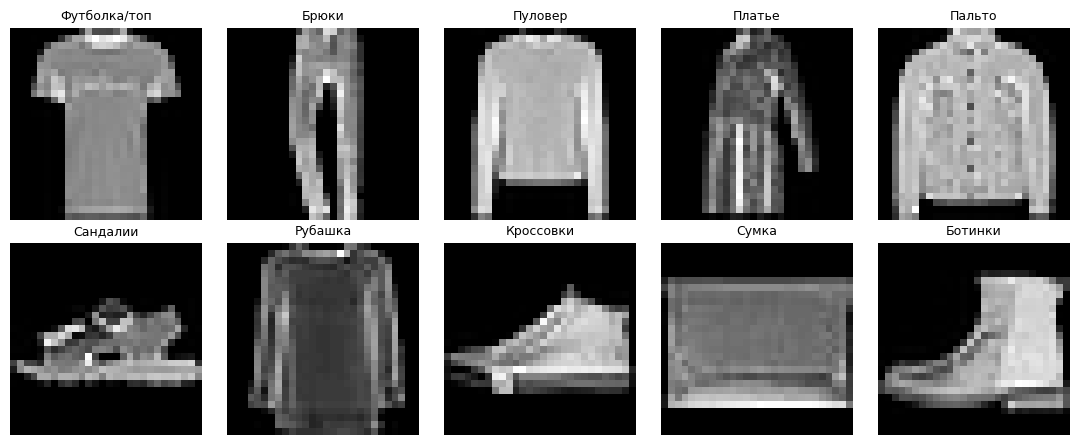

In [7]:
print('обучение / валидация / тест:', len(train_set), len(val_set), len(test_set))
fig, axes = plt.subplots(2, 5, figsize=(11, 4.5))
for label, ax in enumerate(axes.ravel()):
    idx = torch.where(train_set.tensors[1] == label)[0][0]
    ax.imshow((train_set.tensors[0][idx, 0] + 1) / 2, cmap="gray", vmin=0, vmax=1)
    ax.set_title(class_names[label], fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

**3 Модель ViT**
- вход (B, 1, 28, 28)
- патчи через "свёртку" с неперекрывающимеся фильтрами (размер = шагу) -> (B, D, 28/P, 28/P)
- разворачиваем сетку патчей -> (B, N, D); N = количество патчей (квадрат сетки, 28/p ** 2)
- добавляем обучаемый токен класса (как ещё один патч) слева: (B, 1+N, D)
- прибавляем позиционные эмбеддинги, форма не меняется
- блоки трансформера, форма не меняется
- последний LayerNorm, берём токен класса: (B, D)
- линейный классификатор: (B, N_CLASSES)  

**3.1 "Свёрточные" эмбеддинги патчей**

In [8]:
class PatchEmbedding(nn.Module):
    def __init__(self, image_size: int, patch_size: int, in_channels: int, d_embed: int):
        super().__init__()

        assert image_size % patch_size == 0

        self.image_size = image_size
        self.patch_size = patch_size
        self.n_patches = (image_size / patch_size) ** 2

        self.proj = nn.Conv2d(in_channels=in_channels,
                              out_channels=d_embed,
                              kernel_size=(patch_size, patch_size),
                              stride=(patch_size, patch_size)
                              )

    def forward(self, images: Tensor) -> Tensor:
        assert images.ndim == 4
        assert images.shape[-2:] == (self.image_size, self.image_size)

        patches_embed = self.proj(images) # B, d, ps, ps
        patches_embed = torch.flatten(patches_embed, start_dim=2) # B, d, N
        patches_embed = patches_embed.permute(0, 2, 1) # B, N, d

        return patches_embed

In [9]:
patch_test = PatchEmbedding(8, 4, 1, 3)
assert isinstance(patch_test.proj, nn.Conv2d)

with torch.no_grad():
    patch_test.proj.weight.zero_()
    patch_test.proj.bias.zero_()

    patch_test.proj.weight[0, 0] = 1.0
    patch_test.proj.weight[1, 0, 0, 0] = 1.0
    patch_test.proj.weight[2, 0, -1, -1] = 1.0

    actual = patch_test(torch.arange(64.).reshape(1, 1, 8, 8))

expected = torch.tensor([[[216., 0., 27.], [280., 4., 31.],
                          [728., 32., 59.], [792., 36., 63.]]])

torch.testing.assert_close(actual, expected)
assert PatchEmbedding(28, 7, 1, 16)(torch.randn(2, 1, 28, 28)).shape == (2, 16, 16)
print('✓ Порядок и форма выходных токенов корректны.')

✓ Порядок и форма выходных токенов корректны.


**3.2 Двунаправленный multi-head self-attention**
- вход (B, 1+N, D)
- матрицы Q,K,V (через один линейный слой (D, 3*D)) -> разделение на Q,K,V
- приведение Q,K,V к форме (B, n_heads, 1+N, d_head), d_head = d_embed // n_heads
- вычисление внимания: софтмакс от скалярного произведения (масштабировать на корень из размерности головы) запросов и ключей (по оси ключей)
- прореженное (дропаут) внимание взвешивает V
- выходы голов конкатенируются, пропускаются через выходную проекцию и дропаут

In [10]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_embed: int, n_heads: int, dropout: float = 0.0):
        super().__init__()

        assert d_embed % n_heads == 0
        self.n_heads = n_heads
        self.d_head = d_embed // n_heads

        self.qkv = nn.Linear(d_embed, 3 * d_embed)
        self.attn_dropout = nn.Dropout(dropout)

        self.out_proj = nn.Linear(d_embed, d_embed)
        self.proj_dropout = nn.Dropout(dropout)

    def forward(self, x: Tensor) -> tuple[Tensor, Tensor]:
        Q, K, V = self._split_heads(x)
        attn_scores = torch.matmul(Q, K.transpose(-2, -1))
        attn_scores /= self.d_head ** 0.5
        attn_w = torch.softmax(attn_scores, dim=-1)

        output = torch.matmul(self.attn_dropout(attn_w), V)
        output = MultiHeadSelfAttention._merge_heads(output)
        output = self.proj_dropout(self.out_proj(output))

        return (output, attn_w)

    def _split_heads(self, x: Tensor) -> tuple[Tensor, Tensor, Tensor]:
        """
        Получение матриц Q, K, V. Разделение по головам внимания.

        (B, T, D) -> (B, n_heads, T, d_head)
        """
        B, T, _ = x.shape

        qkv = self.qkv(x)
        Q, K, V = torch.chunk(qkv, chunks=3, dim=-1)
        Q = Q.view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        K = K.view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        V = V.view(B, T, self.n_heads, self.d_head).transpose(1, 2)

        return Q, K, V

    @staticmethod
    def _merge_heads(x: Tensor) -> Tensor:
        """
        Объединение голов внимания.

        (B, n_heads, T, d_head) -> (B, T, d_emb)
        """
        B, n_heads, T, d_head = x.shape
        x = x.transpose(1, 2).reshape(B, T, n_heads * d_head)

        return x

In [11]:
seed_everything(0)

attn_test = MultiHeadSelfAttention(16, 4, dropout=0.0).eval()
x = torch.randn(2, 5, 16)
with torch.no_grad():
    output, attn = attn_test(x)

    x_shift = x.clone()
    x_shift[:, -1] += torch.randn(16)

    output_shift, _ = attn_test(x_shift)


assert output.shape == x.shape and attn.shape == (2, 4, 5, 5)
torch.testing.assert_close(attn.sum(dim=-1), torch.ones(2, 4, 5))
assert (attn >= 0).all() and (attn[..., 0, -1] > 0).all(), "Первый токен должен иметь доступ к последнему"
assert (output[:, 0] - output_shift[:, 0]).abs().max() > 1e-6, "Проверьте, что внимание смешивает информацию со всех позиций"

permutation = torch.tensor([3, 0, 4, 1, 2])
with torch.no_grad():
    output_permuted, _ = attn_test(x[:, permutation])
torch.testing.assert_close(output_permuted, output[:, permutation], atol=1e-6, rtol=1e-5)
print('✓ Проверены формы внимания, нормировка строк, смешивание выходов голов внимания и эквивариантность к перестановке.')


✓ Проверены формы внимания, нормировка строк, смешивание выходов голов внимания и эквивариантность к перестановке.


**3.3 MLP для отдельных токенов и блок трансформера**
- MLP независимо к каждому токену
- Linear(D, 4D) -> GELU -> Linear(4D, D) -> Dropout
- pre-norm по последнему измерению


In [12]:
class FeedForward(nn.Module):
    def __init__(self, d_embed: int, dropout: float):
        super().__init__()
        # нормализация будет внутри ViTBlock

        self.net = nn.Sequential(
            nn.Linear(d_embed, 4 * d_embed),
            nn.GELU(),
            nn.Linear(4 * d_embed, d_embed),
            nn.Dropout(dropout)
        )

    def forward(self, x: Tensor) -> Tensor:
        return self.net(x)

In [13]:
class ViTBlock(nn.Module):
    def __init__(self, d_embed: int, n_heads: int, dropout: float):
        super().__init__()

        self.norm1 = nn.LayerNorm(d_embed)
        self.attn = MultiHeadSelfAttention(d_embed, n_heads, dropout)
        self.norm2 = nn.LayerNorm(d_embed)
        self.mlp = FeedForward(d_embed, dropout)

    def forward(self, x: Tensor) -> tuple[Tensor, Tensor]:
        # norm -> self_attn -> residual -> norm -> mlp -> residual

        output, attn_w = self.attn(self.norm1(x))
        output += x

        output = output + self.mlp(self.norm2(output))

        return (output, attn_w)


In [14]:
seed_everything(0)
x = torch.randn(2, 7, 16)

ffn_test = FeedForward(16, dropout=0.0).eval()
with torch.no_grad():
    whole = ffn_test(x)
    separate = torch.cat([ffn_test(x[:, i:i+1]) for i in range(7)], dim=1)

torch.testing.assert_close(whole, separate)

block_test = ViTBlock(16, 4, dropout=0.0).eval()
y, a = block_test(x)
assert y.shape == x.shape and a.shape == (2, 4, 7, 7)
# Если оба внутренних слоя выдают нули, блок обязан возвращать вход без изменений.
with torch.no_grad():
    for p in list(block_test.attn.parameters()) + list(block_test.mlp.parameters()):
        p.zero_()
    identity_output, _ = block_test(x)

torch.testing.assert_close(identity_output, x)
print('✓ Проверены MLP, размерности блоков и resudual connections.')

✓ Проверены MLP, размерности блоков и resudual connections.


**3.4 ViT**
- эмбеддинги патчей
- обучаемый параметр CLS (1,1, d_embed) (для привидения к размеру батча использовать .expand)
- обучаемые позиционные эмбеддинги (1, 1 + N, d_embed)
- блоки ViT через ModuleList
- финальная нормализация эмбеддингов
- голова для классфикации (d_embed, n_classes) применяется только к эмбеддингу класса

In [15]:
class TinyViT(nn.Module):
    def __init__(self,
                 img_size: int = 28,
                 patch_size: int = 4,
                 in_channels: int = 1,
                 n_classes: int = 10,
                 d_embed: int = 128,
                 n_heads: int = 4,
                 depth: int = 3,
                 dropout: float = 0.1):
        super().__init__()

        self.patch_size = patch_size
        self.image_size = img_size
        self.n_patches = (img_size // patch_size) ** 2

        self.patch_embed = PatchEmbedding(img_size, patch_size, in_channels, d_embed)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, d_embed))
        self.pos_embed = nn.Parameter(torch.zeros(1, 1 + self.n_patches, d_embed))
        self.blocks = nn.ModuleList([ViTBlock(d_embed, n_heads, dropout) for _ in range(depth)])
        self.norm = nn.LayerNorm(d_embed)
        self.head = nn.Linear(d_embed, n_classes)

        self.apply(self._init_weights)
        nn.init.normal_(self.cls_token, std=0.02)
        nn.init.normal_(self.pos_embed, std=0.02)


    @staticmethod
    def _init_weights(module: nn.Module):
        if isinstance(module, (nn.Linear, nn.Conv2d)):
            nn.init.normal_(module.weight, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)

    def forward(self, images: Tensor, **kwargs) -> tuple[Tensor, Tensor] | Tensor:
        return self.forward_tokens(self.patch_embed(images), **kwargs)

    def forward_tokens(self,
                       patches: Tensor,
                       use_positions: bool = True,
                       return_attention: bool = False) -> tuple[Tensor, Tensor] | Tensor:
        B, N, _ = patches.shape
        assert N == self.n_patches

        # токен класса и позиционный эмбеддинг
        cls_token = self.cls_token.expand(B, -1, -1)
        x = torch.cat([cls_token, patches], dim=1)
        if use_positions:
            x += self.pos_embed


        attentions = []
        for block in self.blocks:
            x, attn = block(x)
            if return_attention:
                attentions.append(attn)

        # финальная нормализация и классификация
        cls_embed = x[:, 0, :]
        logits = self.head(self.norm(cls_embed))

        return (logits, attentions) if return_attention else logits

In [16]:
seed_everything(0)

test_model = TinyViT(d_embed=32, n_heads=4, depth=2, dropout=0.0)
images, labels = train_set.tensors[0][:4], train_set.tensors[1][:4]

logits, attentions = test_model(images, return_attention=True)
assert logits.shape == (4, N_CLASSES)
assert len(attentions) == 2 and attentions[0].shape == (4, 4, 50, 50)

loss = F.cross_entropy(logits, labels)
assert torch.isfinite(loss)
assert abs(loss.item() - math.log(N_CLASSES)) < 0.5

loss.backward()
for name, p in test_model.named_parameters():
    assert p.grad is not None and torch.isfinite(p.grad).all(), f"Градиент отсутствует или содержит NaN/Inf: {name}"
for p in (test_model.patch_embed.proj.weight, test_model.cls_token, test_model.pos_embed):
    assert p.grad.abs().sum() > 0, 'Один из обучаемых входных компонентов не получает градиент.'
print(f"✓ Формы и градиенты ViT корректны; начальные потери {loss.item():.3f} (равномерное предсказание ≈ {math.log(10):.3f}).")

✓ Формы и градиенты ViT корректны; начальные потери 2.396 (равномерное предсказание ≈ 2.303).


**4 Обучение**
- все параметры (свёртка, cls, позиции, внимание, MLP, голова) обучаются совместно

In [17]:
IMAGE_SIZE = 28
IN_CHANNELS = 1
PATCH_SIZE = 4
EMBED_DIM = 128
NUM_HEADS = 4
DEPTH = 3
DROPOUT = 0.1
BATCH_SIZE = 128
EPOCHS = 8
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-2
assert IMAGE_SIZE % PATCH_SIZE == 0
assert EMBED_DIM % NUM_HEADS == 0

def model_config(patch_size: int) -> dict:
    return dict(img_size=IMAGE_SIZE, patch_size=patch_size, in_channels=IN_CHANNELS,
                n_classes=N_CLASSES, d_embed=EMBED_DIM, n_heads=NUM_HEADS,
                depth=DEPTH, dropout=DROPOUT)


In [18]:
@torch.inference_mode()
def evaluate(model: nn.Module, loader: torch.utils.data.DataLoader) -> dict[str, float]:
    model.eval()

    total_loss, correct, total = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)

        total_loss += F.cross_entropy(logits, y, reduction="sum").item()
        correct += (logits.argmax(dim=-1) == y).sum().item()
        total += len(y)

    return {"loss": total_loss / total, "accuracy": correct / total}


def plot_history(result: dict, title: str):
    '''
    Вспомогательная функция построения графиков обучения.
    '''
    h = result["history"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    for ax, train_key, val_key, ylabel in [
        (axes[0], "train_loss", "val_loss", 'Кросс-энтропия'),
        (axes[1], "train_acc", "val_acc", 'Доля верных ответов')
    ]:
        ax.plot([r["epoch"] for r in h], [r[train_key] for r in h], label='обучение (в течение эпохи)')
        ax.plot([r["epoch"] for r in h], [r[val_key] for r in h], label='валидация')
        ax.axvline(result["best_epoch"], ls="--", color="gray", alpha=0.6, label='выбранная эпоха')
        ax.set(xlabel='Эпоха', ylabel=ylabel, title=f"{title}: {ylabel}")
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()



In [19]:
def fit_model(model: nn.Module) -> dict:
    seed_everything(SEED)

    train_loader = make_loader(train_set, shuffle=True)
    val_loader = make_loader(val_set)

    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

    baseline = evaluate(model, val_loader)
    print(f"P={model.patch_size} | параметров={sum(p.numel() for p in model.parameters()):,} | "
          f"валидация до обучения: потери={baseline['loss']:.3f}, доля верных ответов={baseline['accuracy']:.1%}")

    history = []
    best_loss, best_state, best_epoch = float("inf"), None, None

    train_seconds = 0.0
    synchronize()
    wall_start = time.perf_counter()

    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss, correct, total = 0.0, 0, 0

        synchronize()
        start = time.perf_counter()

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)

            loss = F.cross_entropy(logits, y)
            loss.backward()

            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            optimizer.zero_grad(set_to_none=True)

            total_loss += loss.item() * len(y)
            correct += (logits.argmax(-1) == y).sum().item()
            total += len(y)

        synchronize()
        epoch_seconds = time.perf_counter() - start
        train_seconds += epoch_seconds

        validation = evaluate(model, val_loader)
        history.append(
            {
                "epoch": epoch,
                "train_loss": total_loss / total,
                "train_acc": correct / total,
                "val_loss": validation["loss"],
                "val_acc": validation["accuracy"]
            }
        )

        if validation["loss"] < best_loss:
            best_loss, best_epoch = validation["loss"], epoch
            best_state = {
                name: values.detach().cpu().clone() for name, values in model.state_dict().items()
            }

        scheduler.step()
        print(f"эпоха {epoch:2d}/{EPOCHS} | потери на обучении {total_loss/total:.3f}, доля верных {correct/total:.1%} | "
              f"потери на валидации {validation['loss']:.3f}, доля верных {validation['accuracy']:.1%} | обучение {epoch_seconds:.1f}с")


    synchronize()
    wall_seconds = time.perf_counter() - wall_start

    model.load_state_dict(best_state)
    model.eval()
    Path("checkpoints").mkdir(exist_ok=True)
    torch.save(
        {
            "state_dict": best_state,
            "config": model_config(model.patch_size),
            "seed": SEED,
            "best_epoch": best_epoch,
            "model_class": type(model).__name__
        },
        f"checkpoints/{type(model).__name__}_p{model.patch_size}.pt"
    )

    best = history[best_epoch - 1]
    print(f"Лучшая эпоха: {best_epoch}; обучение {train_seconds:.1f}с; полное время {wall_seconds:.1f}с")

    result = dict(
        model=model,
        history=history,
        baseline=baseline,
        best_epoch=best_epoch,
        val_loss=best["val_loss"],
        val_acc=best["val_acc"],
        train_seconds=train_seconds,
        wall_seconds=wall_seconds,
        parameters=sum(p.numel() for p in model.parameters()),
        updates=EPOCHS * len(train_loader)
    )

    return result

P=4 | параметров=605,066 | валидация до обучения: потери=2.339, доля верных ответов=10.1%
эпоха  1/8 | потери на обучении 1.708, доля верных 39.5% | потери на валидации 1.311, доля верных 53.2% | обучение 2.2с
эпоха  2/8 | потери на обучении 1.082, доля верных 62.5% | потери на валидации 0.901, доля верных 68.0% | обучение 1.9с
эпоха  3/8 | потери на обучении 0.830, доля верных 70.7% | потери на валидации 0.776, доля верных 72.2% | обучение 1.1с
эпоха  4/8 | потери на обучении 0.708, доля верных 74.9% | потери на валидации 0.675, доля верных 76.5% | обучение 1.1с
эпоха  5/8 | потери на обучении 0.630, доля верных 77.4% | потери на валидации 0.643, доля верных 76.5% | обучение 1.1с
эпоха  6/8 | потери на обучении 0.586, доля верных 79.3% | потери на валидации 0.592, доля верных 79.5% | обучение 1.1с
эпоха  7/8 | потери на обучении 0.542, доля верных 81.3% | потери на валидации 0.566, доля верных 81.3% | обучение 1.1с
эпоха  8/8 | потери на обучении 0.518, доля верных 81.8% | потери на в

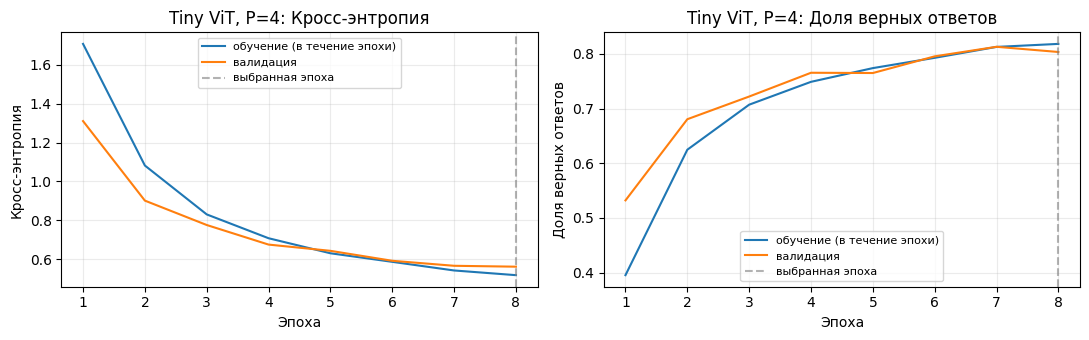

In [20]:
model = TinyViT(**model_config(PATCH_SIZE)).to(device)
main_result = fit_model(model)
model = main_result["model"]
plot_history(main_result, f"Tiny ViT, P={PATCH_SIZE}")

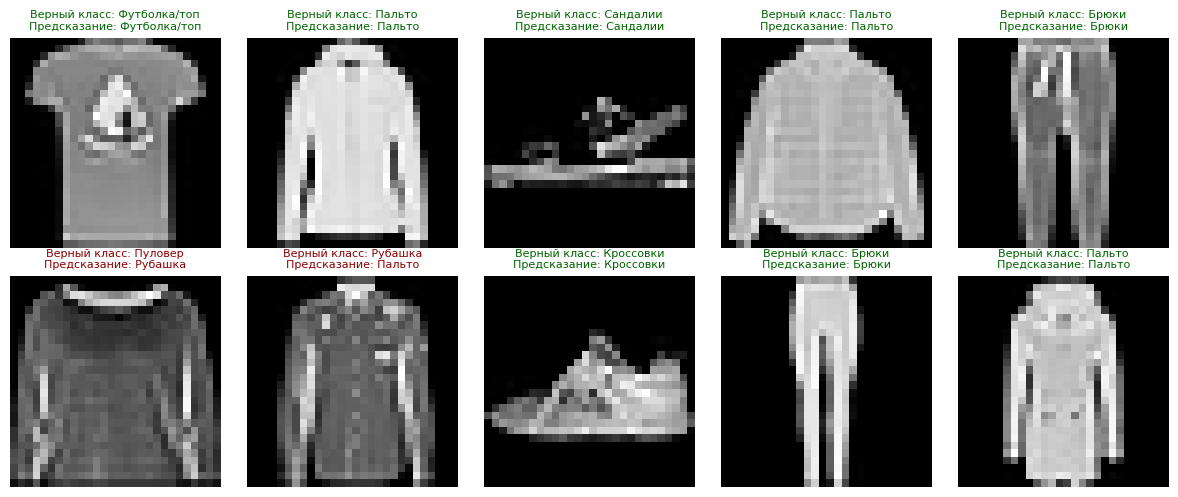

In [21]:
# Фиксируем валидационную подвыборку для двух следующих исследований.
exp_x = val_set.tensors[0][:N_IMG_EXPERIMENT].to(device)
exp_y = val_set.tensors[1][:N_IMG_EXPERIMENT].to(device)
model.eval()
with torch.no_grad():
    exp_logits = model(exp_x)
    exp_predictions = exp_logits.argmax(dim=-1)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.ravel()):
    true_id, pred_id = int(exp_y[i]), int(exp_predictions[i])
    ax.imshow((exp_x[i, 0].cpu() + 1) / 2, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Верный класс: {class_names[true_id]}\nПредсказание: {class_names[pred_id]}", fontsize=8,
                 color="darkgreen" if true_id == pred_id else "darkred")
    ax.axis("off")
plt.tight_layout(); plt.show()


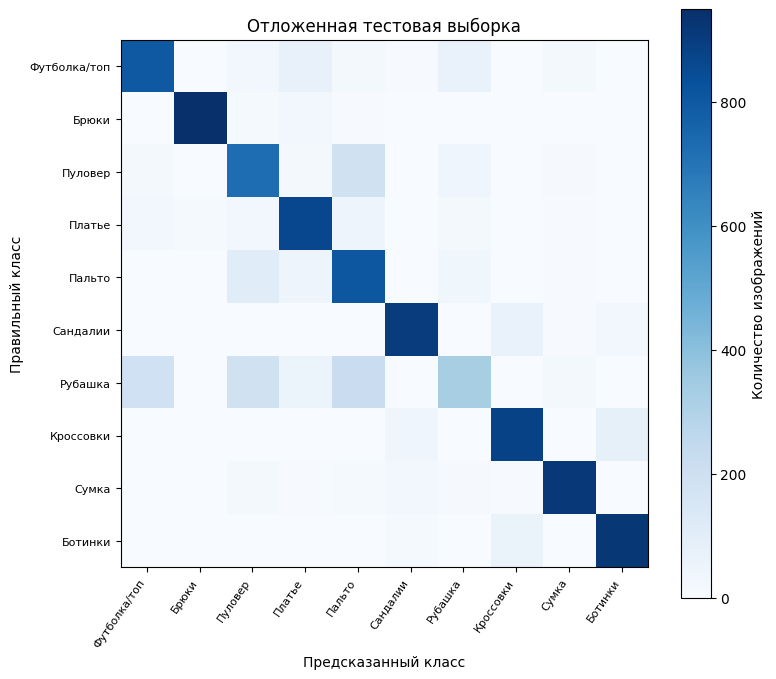

In [22]:
confusion = torch.zeros(N_CLASSES, N_CLASSES, dtype=torch.long)
model.eval()
with torch.no_grad():
    for x, y in make_loader(test_set):
        prediction = model(x.to(device)).argmax(dim=-1).cpu()
        confusion += torch.bincount(y * N_CLASSES + prediction,
                                    minlength=N_CLASSES ** 2).reshape(N_CLASSES, N_CLASSES)


fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(confusion.numpy(), cmap="Blues")
ax.set_xticks(range(N_CLASSES), labels=class_names, rotation=55, ha="right", fontsize=8)
ax.set_yticks(range(N_CLASSES), labels=class_names, fontsize=8)
ax.set(xlabel='Предсказанный класс', ylabel='Правильный класс', title=f"Отложенная тестовая выборка")
plt.colorbar(im, ax=ax, label='Количество изображений')
plt.tight_layout(); plt.show()


**5 Эксперимент 1: знает ли ViT, где должен находиться патч?**
- как изменение порядка патчей влияет на результат

A) Перестановка патчей до добавления позиционных эмбеддингов
    - содержимому патча соответствует чужая позиция
    - содержимое и позиция рассогласованы, порядок изменён
    - то есть проверяем используется ли связка (патч, позиция), привязана ли информация к позиции
    - качество упадет (если PE используется) и не изменится (если не использутеся)

B) После (перестановка вместе с позиционными, не затрагивая CLS)
    - сохраняется связь между содержимым патча и позицией
    - но меняется сам порядок токенов
    - то есть проверяем инвариантна ли модель к порядку
    - если модель инвариантна к порядку, то качество не изменится (иначе --- упадёт)

C) Отключаем позиционные эмбеддинги, патчи не переставляем
    - изменяются распределения входов: модель обучилась для одного, а на инференсе приходит другое
    - качество упадёт (но это не обязательно следствие важности позиционных эмбеддингов, скорее это показывает что модель не устойчива к удалению компонента

D) Обучение с нуля без позиционных эмбеддингов вообще
    - веса внимания и MLP учаться иначе, без позиционной информации
    - в этом случае распределение при обучении и при инференсе согласованы
    - качество зависит от задачи (если для задачи важна позиция объекта на картинке, то упадёт)
    - проверяем нужен ли PE для такой задачи


**5.1 Изменение логики модели для экспериментов 1-3**
- затрагивается только инференс, достаточно переопределить .forward()
- вариант A: до добавления позиционных эмбеддингов, перестановка patches (по измерению токенов)
- вариант B: после, вместе с PE, учесть токен СLS
- permutations[j] = индекс исходного патча, который окажется на позиции j

In [23]:
def patch_order_from_seed(n_patches: int, seed: int, device: torch.device):
    if seed is None:
        return

    generator = torch.Generator(device="cpu").manual_seed(seed)
    permutation = torch.randperm(n_patches, generator=generator).to(device)

    return permutation


In [24]:
class TinyViTShuffle(TinyViT):
    def forward(self,
                images: Tensor,
                seed: int | None = None,
                permutation_stage: str | None = None,
                use_positions: bool = True,
                return_attention: bool = False) -> Tensor | tuple[Tensor, Tensor]:

        patches = self.patch_embed(images)
        B, N, D = patches.shape

        assert N == self.n_patches
        if permutation_stage is not None:
            assert permutation_stage in ("before_pos", "after_pos")
            assert seed is not None
            permutation = patch_order_from_seed(N, seed, patches.device)

        if permutation_stage == "before_pos":
            patches = patches[:, permutation, :]

        # токен класса и позиционный эмбеддинг
        cls_token = self.cls_token.expand(B, -1, -1)
        x = torch.cat([cls_token, patches], dim=1)
        if use_positions:
            x += self.pos_embed

        if permutation_stage == "after_pos":
            cls_part = x[:, :1, :]
            patch_part = x[:, 1:, :][:, permutation, :]
            x = torch.cat([cls_part, patch_part], dim=1)

        attentions = []
        for block in self.blocks:
            x, attn = block(x)
            if return_attention:
                attentions.append(attn)

        logits = self.head(self.norm(x)[:, 0])

        return logits if not return_attention else (logits, attentions)

In [25]:
base_model = main_result["model"]
base_model.eval()
shuffle_model = TinyViTShuffle(**model_config(base_model.patch_size)).to(device)
shuffle_model.load_state_dict(base_model.state_dict(), strict=True)
shuffle_model.eval()

check_images = exp_x[:8]
with torch.no_grad():
    base_logits, base_attention = base_model(check_images, return_attention=True)
    copied_logits, copied_attention = shuffle_model(check_images, permutation_stage=None, return_attention=True)

    torch.testing.assert_close(copied_logits, base_logits, atol=2e-5, rtol=1e-4)
    for original_attention, new_attention in zip(base_attention, copied_attention):
        torch.testing.assert_close(new_attention, original_attention, atol=2e-5, rtol=1e-4)

    # Сам по себе seed не должен включать перестановку.
    torch.testing.assert_close(shuffle_model(check_images, seed=0), base_logits, atol=2e-5, rtol=1e-4)

    rng_before = torch.random.get_rng_state().clone()
    seeded_first = shuffle_model(check_images, seed=0, permutation_stage="before_pos")
    seeded_second = shuffle_model(check_images, seed=0, permutation_stage="before_pos")

    torch.testing.assert_close(seeded_first, seeded_second)
    assert torch.equal(rng_before, torch.random.get_rng_state()), 'Не сбрасывайте и не расходуйте глобальный генератор для создания перестановки.'

order0 = patch_order_from_seed(shuffle_model.n_patches, 0, device)
order1 = patch_order_from_seed(shuffle_model.n_patches, 1, device)

assert not torch.equal(order0, order1), 'Эти два seed должны давать разные перестановки патчей.'
assert torch.equal(order0.sort().values, torch.arange(shuffle_model.n_patches, device=device))
assert base_model.cls_token.data_ptr() != shuffle_model.cls_token.data_ptr(), 'Используйте отдельные экземпляры моделей.'
print('✓ Веса скопированы; permutation_stage=None совпадает с TinyViT; seed=0 воспроизводим; глобальный генератор не изменён.')

✓ Веса скопированы; permutation_stage=None совпадает с TinyViT; seed=0 воспроизводим; глобальный генератор не изменён.


**Эксперименты A-C с обученными параметрами**
- загрузка обученных весов

In [26]:
SHUFFLE_SEED = SEED + 1
shuffle_model.eval()

# Изображения для этих экспериментов.
exp_x = val_set.tensors[0][:N_IMG_EXPERIMENT].to(device)
exp_y = val_set.tensors[1][:N_IMG_EXPERIMENT].to(device)

with torch.inference_mode():
    original = shuffle_model(exp_x)

    # перестановка до PE, PE включены
    before_positions = shuffle_model(exp_x, SHUFFLE_SEED, permutation_stage="before_pos", use_positions=True)

    # после PE, PE включены
    after_positions = shuffle_model(exp_x, SHUFFLE_SEED, permutation_stage="after_pos", use_positions=True)

    # без перестановок и без PE
    no_positions = shuffle_model(exp_x, use_positions=False)

In [27]:
def shuffle_image_patches(images: Tensor, seed: int, patch_size: int) -> Tensor:
    '''
    Вспомогательная функция перестановки патчей изображения для визуализации.
    '''
    grid = images.shape[-1] // patch_size
    permutation = patch_order_from_seed(grid * grid, seed, images.device)
    if permutation is None:
        return images.clone()
    result = torch.empty_like(images)
    for destination, source in enumerate(permutation.cpu().tolist()):
        dr, dc = divmod(destination, grid)
        sr, sc = divmod(source, grid)
        result[:, :, dr*patch_size:(dr+1)*patch_size, dc*patch_size:(dc+1)*patch_size] = \
            images[:, :, sr*patch_size:(sr+1)*patch_size, sc*patch_size:(sc+1)*patch_size]
    return result

# Проверка: перестановка целых патчей изображения эквивалентна перестановке выходов свёртки.
with torch.no_grad():
    shuffled_images = shuffle_image_patches(exp_x, SHUFFLE_SEED, shuffle_model.patch_size)
    shuffled_image_logits = shuffle_model(shuffled_images)
torch.testing.assert_close(shuffled_image_logits, before_positions, atol=2e-5, rtol=1e-4)

Теперь сравним случаи A–C: посмотрим, как меняются логиты и предсказанные классы.

A: содержимое переставлено, positional encodings фиксированы
  max |разница логитов|=8.23e+00; изменено предсказаний=71/100
B: содержимое и positional encodings переставлены вместе
  max |разница логитов|=9.54e-07; изменено предсказаний=0/100
C: positional encodings отключены только при инференсе
  max |разница логитов|=7.14e+00; изменено предсказаний=53/100


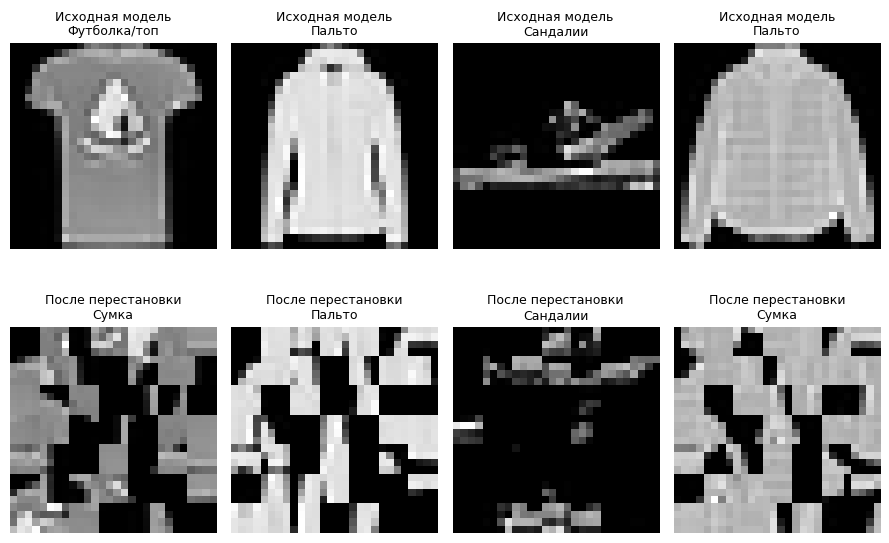

In [28]:
shuffle_results = {}
def report_shuffle(name: str, reference: Tensor, changed: Tensor):
    difference = (reference - changed).abs().max().item()
    changed_labels = (reference.argmax(-1) != changed.argmax(-1)).sum().item()
    shuffle_results[name] = dict(max_logit_difference=difference, changed_labels=changed_labels)
    print(f"{name}\n  max |разница логитов|={difference:.2e}; "
          f"изменено предсказаний={changed_labels}/{len(reference)}")

report_shuffle('A: содержимое переставлено, positional encodings фиксированы', original, before_positions)
report_shuffle('B: содержимое и positional encodings переставлены вместе', original, after_positions)
report_shuffle('C: positional encodings отключены только при инференсе', original, no_positions)

fig, axes = plt.subplots(2, 4, figsize=(9, 6))
for i in range(4):
    for row, batch, logits, title in [(0, exp_x, original, 'Исходная модель'),
                                       (1, shuffled_images, before_positions, 'После перестановки')]:
        axes[row, i].imshow((batch[i, 0].cpu() + 1) / 2, cmap="gray", vmin=0, vmax=1)
        axes[row, i].set_title(f"{title}\n{class_names[int(logits[i].argmax())]}", fontsize=9)
        axes[row, i].axis("off")
plt.tight_layout(h_pad=2.0); plt.show()





Измерим долю верных ответов на валидации для вариантов A–C:


Исходная модель: обучение и оценка с positional encodings: доля верных ответов на валидации = 80.3%
A: перестановка содержимого до добавления positional encodings: доля верных ответов на валидации = 26.3%
B: содержимое и positional encodings переставлены вместе: доля верных ответов на валидации = 80.3%
C: positional encodings отключены только при инференсе: доля верных ответов на валидации = 42.1%


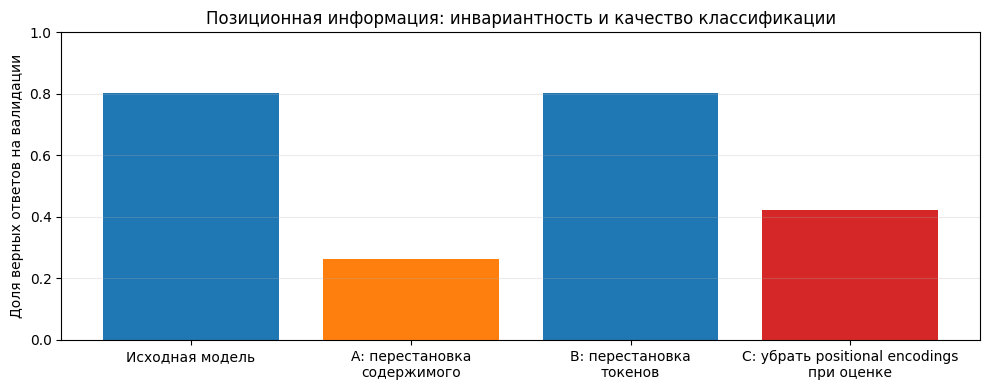

In [29]:
@torch.inference_mode()
def evaluate_variant(model: nn.Module, loader: torch.utils.data.DataLoader, **forward_kwargs) -> float:
    model.eval()
    correct, total = 0, 0
    for x, y in loader:
        predictions = model(x.to(device), **forward_kwargs).argmax(dim=-1)
        correct += (predictions == y.to(device)).sum().item()
        total += len(y)
    return correct / total

# Оцениваем на ВСЕЙ валидации, а не только на 100 примерах из проверок перестановки.
validation_cases = [
    ('Исходная модель: обучение и оценка с positional encodings', shuffle_model, {}),
    ('A: перестановка содержимого до добавления positional encodings', shuffle_model,
     {"seed": SHUFFLE_SEED, "permutation_stage": "before_pos"}),
    ('B: содержимое и positional encodings переставлены вместе', shuffle_model,
     {"seed": SHUFFLE_SEED, "permutation_stage": "after_pos"}),
    ('C: positional encodings отключены только при инференсе', shuffle_model, {"use_positions": False}),
]

# Вычисляем долю верных ответов на валидации.
position_accuracies = {}
for label, variant, kwargs in validation_cases:
    accuracy = evaluate_variant(variant, make_loader(val_set), **kwargs)
    position_accuracies[label] = accuracy
    print(f"{label}: доля верных ответов на валидации = {accuracy:.1%}")

# Визуализация.
fig, ax = plt.subplots(figsize=(10, 4))
short_names = ['Исходная модель', 'A: перестановка\nсодержимого', 'B: перестановка\nтокенов', 'C: убрать positional encodings\nпри оценке']
ax.bar(short_names, list(position_accuracies.values()), color=["tab:blue", "tab:orange", "tab:blue", "tab:red"])
ax.set(ylabel='Доля верных ответов на валидации', ylim=(0, 1), title='Позиционная информация: инвариантность и качество классификации')
ax.grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()



Какие результаты вы получили? Совпали ли они с вашими предварительными ожиданиями?

1) A) содержимое переставлено, positional encodings фиксированы
    - рассогласование содержимого и позиции критически влияет на качество.

2) B) содержимое и positional encodings переставлены вместе
    - модель инвариантна к порядку токенов: качество не изменилось.

3) C) positional encodings отключены только при инференсе
    - out of distribution: на вход приходит совсем другое распределение, критически влияет на качество.


**5.3 Обучение новой модели без PE вообще**
- отнаследовать и вменить use_positions=False

In [30]:
class TinyViTNoPositions(TinyViTShuffle):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)

        self.pos_embed.requires_grad_(False)

    def forward(self,
                images: Tensor,
                seed: int | None = None,
                permutation_stage: str | None = None,
                return_attention: bool = False) -> Tensor | tuple[Tensor, Tensor]:

        result = super().forward(images, seed, permutation_stage, use_positions=False, return_attention=return_attention)

        return result

In [31]:
# Эта маленькая необученная модель нужна только для проверки нового forward()
no_pos_check = TinyViTNoPositions(d_embed=32, n_heads=4, depth=1, dropout=0.0).to(device)
no_pos_check.eval()

with torch.no_grad():
    expected_no_pos = TinyViTShuffle.forward(no_pos_check, check_images, use_positions=False)
    actual_no_pos = no_pos_check(check_images)

    torch.testing.assert_close(actual_no_pos, expected_no_pos, atol=2e-5, rtol=1e-4)

    # Сильное изменение неиспользуемых positional encodings не должно влиять на результат.
    no_pos_check.pos_embed.add_(100.0)
    torch.testing.assert_close(no_pos_check(check_images), actual_no_pos, atol=2e-5, rtol=1e-4)


no_pos_check.train()
F.cross_entropy(no_pos_check(check_images), exp_y[:len(check_images)]).backward()

assert no_pos_check.pos_embed.grad is None
assert no_pos_check.patch_embed.proj.weight.grad is not None

print('✓ Positional encodings отключены при обучении и инференсе; проекция патчей получает градиенты.')
del no_pos_check



✓ Positional encodings отключены при обучении и инференсе; проекция патчей получает градиенты.


Инициализация и обучение

P=4 | параметров=605,066 | валидация до обучения: потери=2.348, доля верных ответов=8.9%
эпоха  1/8 | потери на обучении 1.749, доля верных 37.8% | потери на валидации 1.458, доля верных 49.8% | обучение 1.1с
эпоха  2/8 | потери на обучении 1.285, доля верных 54.3% | потери на валидации 1.243, доля верных 53.8% | обучение 1.1с
эпоха  3/8 | потери на обучении 1.079, доля верных 60.7% | потери на валидации 1.041, доля верных 62.6% | обучение 1.1с
эпоха  4/8 | потери на обучении 0.974, доля верных 64.8% | потери на валидации 0.971, доля верных 65.2% | обучение 1.2с
эпоха  5/8 | потери на обучении 0.902, доля верных 67.3% | потери на валидации 0.883, доля верных 68.0% | обучение 1.1с
эпоха  6/8 | потери на обучении 0.845, доля верных 69.9% | потери на валидации 0.809, доля верных 71.6% | обучение 1.1с
эпоха  7/8 | потери на обучении 0.794, доля верных 72.1% | потери на валидации 0.793, доля верных 71.7% | обучение 1.1с
эпоха  8/8 | потери на обучении 0.775, доля верных 72.7% | потери на ва

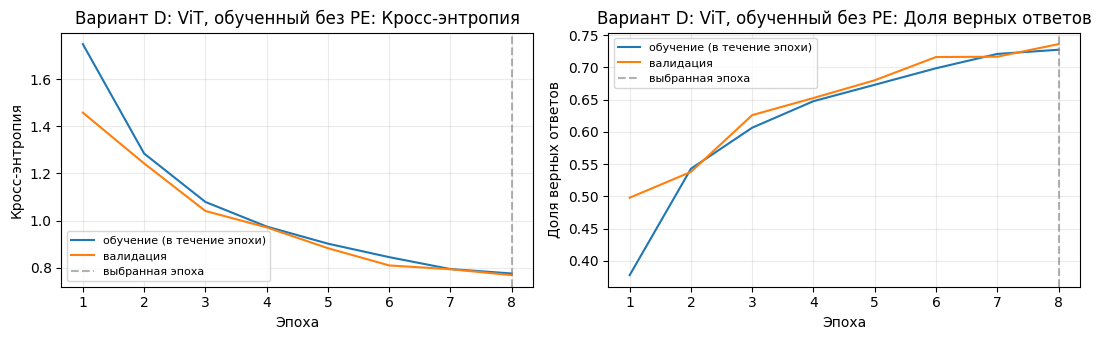

In [32]:
seed_everything(SEED)

no_pos_model = TinyViTNoPositions(**model_config(PATCH_SIZE)).to(device)
no_pos_result = fit_model(no_pos_model)
no_pos_model = no_pos_result["model"]

plot_history(no_pos_result, "Вариант D: ViT, обученный без PE")

In [33]:
no_pos_model.eval()
with torch.inference_mode():
    trained_no_positions = no_pos_model(exp_x)


report_shuffle('D: модель обучена без positional encodings', original, trained_no_positions)


D: модель обучена без positional encodings
  max |разница логитов|=4.05e+00; изменено предсказаний=24/100


Логиты получены из двух по-разному обученных моделей (как минимум, разные инициализации). Сравним качество на валидационной выборке:

D: обучение и оценка без ositional encodings: доля верных ответов на валидации = 73.6%


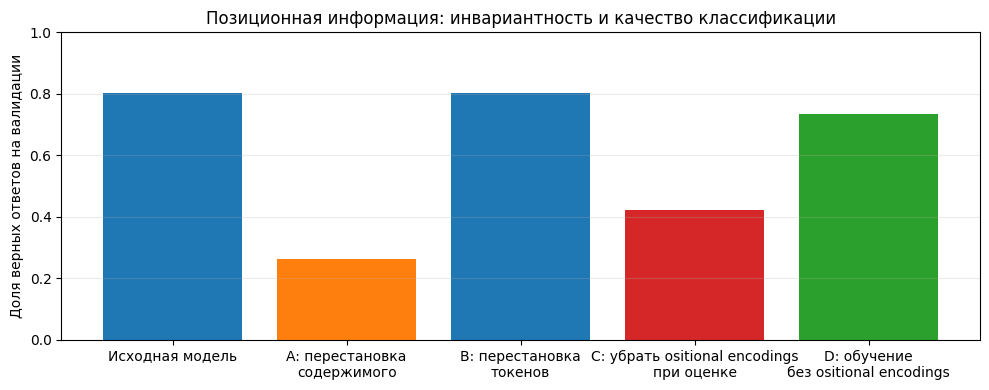

In [34]:
# A–C уже оценены; добавляем D один раз, в том числе при повторном запуске ячейки.
validation_cases = validation_cases[:4] + [
    ('D: обучение и оценка без ositional encodings', no_pos_model, {})
]

# Вычисляем долю верных ответов на валидации.
label, variant, kwargs = validation_cases[-1]
accuracy = evaluate_variant(variant, make_loader(val_set), **kwargs)
position_accuracies[label] = accuracy
print(f"{label}: доля верных ответов на валидации = {accuracy:.1%}")

# Визуализация.
fig, ax = plt.subplots(figsize=(10, 4))
short_names = ['Исходная модель', 'A: перестановка\nсодержимого', 'B: перестановка\nтокенов', 'C: убрать ositional encodings\nпри оценке', 'D: обучение\nбез ositional encodings']
ax.bar(short_names, list(position_accuracies.values()), color=["tab:blue", "tab:orange", "tab:blue", "tab:red", "tab:green"])
ax.set(ylabel='Доля верных ответов на валидации', ylim=(0, 1), title='Позиционная информация: инвариантность и качество классификации')
ax.grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()



**Обсуждение**
1) Приведите максимальные различия логитов и количество изменившихся предсказаний для A–D. Во всех четырёх случаях используйте исходную модель как точку отсчёта. Чем различаются изменения в C и D? Почему разница логитов в D не измеряет изолированно эффект позиционных эмбеддингов?
    - A: содержимое переставлено, positional encodings фиксированы
        - max |разница логитов|=8.23e+00; изменено предсказаний=71/100
    - B: содержимое и positional encodings переставлены вместе
        - max |разница логитов|=9.54e-07; изменено предсказаний=0/100
    - C: positional encodings отключены только при инференсе
        - max |разница логитов|=7.14e+00; изменено предсказаний=53/100
    - D: модель обучена без positional encodings
        - max |разница логитов|=4.05e+00; изменено предсказаний=24/100
    - для C модель обучалась с позиционными эмбеддингами, поэтому их отключение на инференсе искажает ожидаемый вход
    - для D модель сразу училась работать без позиционных эмбеддингов
2) Объясните разницу между перемещением содержимого до или после добавления positional encodings. Почему выходы для патчей эквивариантны относительно перестановки, а итоговое предсказание по CLS инвариантно? Опишите, что происходит с Q, K, V и строками и столбцами матрицы внимания.
    - Перестановка до добавления позиционных эмбеддингов нарушает связку (содержимое, позиция). После --- нет, происходит просто перестановка элементов последовательности.
    - Перестановка токенов переставляет строки Q, K, V. Далее в Q @ K.T переставляются обе оси. Далее софтмакс по строкам, от столбцов не зависит. Далее матричное умножение на V (с переставленными строками). В общем, перестановка сохраняется на всех слоях.
    - CLS добавляется слева, не участвует в перестановке. Далее считывает все токены через attention, не зависящий от порядка.  
3) Сравните долю верных ответов исходной модели, C и D на валидации. Достаточно ли одного C, чтобы судить о пользе позиционных эмбеддингов? Что добавляет D и какие ограничения остаются?
    - Нет, C скорее показывает, что уже обученная с PE модель не может работать без PE. То есть, что модель их использует.
    - D показывает, что модель может обучиться без PE, но не показывает сопоставимого качества. То есть PE всё же добавляет информацию.
    - Ограничения: seed (инициализация), кол-во эпох, кол-во экспериментов.
4) Почему для seed перестановки нужен локальный генератор, а не сброс глобального seed внутри forward?
    - Чтобы изолировать случайность внутри вызова функции перестановки и не влиять на обучение моделей.

**6. Эксперимент 2. Патчи с высоким весом внимания**
- патчи с высоким значением после rollout маскируются
- rollout = усреднение (по головам) внимания на каждом слое (остальные слои приближаются тождественным преобразованием)
- маскирование таких патчей должно приводить к более сильному падению качества нежели обычных патчей
- в каждом слое головы внимания усредняются: A_l (B, T, T)
- учет обратной связи: B_l = A_l + I, нормировка по строкам
- далее R_0 = I, R_l = B_l * R_{l-1}

In [35]:
def attention_rollout(attentions: list[Tensor]) -> Tensor:
    # B, n_heads, T, d_emb
    B, _, T, _ = attentions[0].shape

    identity = torch.eye(T, device=attentions[0].device, dtype=attentions[0].dtype) # T, T
    rollout = identity.unsqueeze(0).expand(B, -1, -1) # B, T, T

    for a in attentions:
        a = a.mean(dim=1) # B, T, T
        b = a + torch.eye(T, device=a.device) # B, d_emb
        b /= b.sum(dim=-1, keepdim=True)
        rollout = torch.matmul(b, rollout)

    # строка для CLS, столбцы все кроме CLS
    return rollout[:, 0, 1:]



In [36]:
# CLS, p1, p2: в слое 1 токен p1 читает p2; в слое 2 CLS читает p1.
a1 = torch.tensor([[1., 0., 0.], [0., 0., 1.], [0., 0., 1.]])[None, None]
a2 = torch.tensor([[0., 1., 0.], [0., 1., 0.], [0., 0., 1.]])[None, None]
torch.testing.assert_close(attention_rollout([a1, a2]), torch.tensor([[0.25, 0.25]]))
assert not torch.allclose(attention_rollout([a2, a1]), torch.tensor([[0.25, 0.25]])), 'Порядок этих двух слоёв влияет на результат.'
# Несколько голов и изображений: усреднение должно идти по оси голов.
torch.testing.assert_close(attention_rollout([a1.expand(2, 3, -1, -1), a2.expand(2, 3, -1, -1)]),
                           torch.tensor([[0.25, 0.25], [0.25, 0.25]]))
print('✓ Проверены композиция rollout, нормировка residual, оси батча/голов и выбор CLS.')

✓ Проверены композиция rollout, нормировка residual, оси батча/голов и выбор CLS.


**6.2 Ранжирование патчей по значимости rollout**
- ранжирование (high/low) вычисляется один раз для каждого исходного изображения
- остлеживаем исходного предсказанный класс
- -> перестановка N индексов для каждого изображения (B, N)

In [37]:
def rank_patches(scores,
                 strategy: str,
                 generator: torch.Generator | None = None) -> torch.Tensor:
    """(B, N) -> (B, N)"""
    n_images, n_indices = scores.shape

    if strategy == "random":
        return torch.stack([torch.randperm(n_indices, generator=generator) for _ in range(n_images)]).to(scores.device)

    assert strategy in ("low", "high")
    flag = strategy == "high"
    ranked_indices = torch.argsort(scores, dim=-1, descending=flag)

    return ranked_indices

def mask_patches(images: Tensor,
                 ranking: Tensor,
                 count: int,
                 patch_size: int,
                 fill_value: float = 0.0) -> Tensor:
    B, _, H, W = images.shape
    gh, gw = H // patch_size, W // patch_size

    assert H % patch_size == W % patch_size == 0
    assert ranking.shape == (B, gh * gw) and 0 <= count <= gh * gw

    selected = torch.zeros(B, gh * gw, device=images.device, dtype=torch.bool)
    selected.scatter_(1, ranking[:, :count], True)

    pixel_mask = selected.reshape(B, 1, gh, gw)
    pixel_mask = pixel_mask.repeat_interleave(patch_size, dim=2).repeat_interleave(patch_size, dim=3)

    return images.masked_fill(pixel_mask, fill_value)



In [38]:
scores_test = torch.tensor([[0.2, 0.7, 0.1], [0.8, 0.1, 0.3]])
assert torch.equal(rank_patches(scores_test, "high"), torch.tensor([[1, 0, 2], [0, 2, 1]]))
assert torch.equal(rank_patches(scores_test, "low"), torch.tensor([[2, 0, 1], [1, 2, 0]]))
random_order = rank_patches(scores_test, "random", torch.Generator().manual_seed(SEED))
assert torch.equal(random_order.sort(-1).values, torch.arange(3).expand(2, -1))
ones = torch.ones(2, 1, IMAGE_SIZE, IMAGE_SIZE)
ordered = torch.arange((IMAGE_SIZE // PATCH_SIZE) ** 2).expand(2, -1)
torch.testing.assert_close(mask_patches(ones, ordered, 0, PATCH_SIZE), ones)
assert (mask_patches(ones, ordered, 3, PATCH_SIZE) == 0).sum().item() == 2 * 3 * PATCH_SIZE ** 2
assert mask_patches(ones, ordered, ordered.shape[1], PATCH_SIZE).abs().sum() == 0
print('✓ Проверены ранжирование, отсутствие маскирования, площадь патчей и полное маскирование.')

✓ Проверены ранжирование, отсутствие маскирования, площадь патчей и полное маскирование.


**6.3 Сравнение кривых маскирования**

Код в ячейке ниже маскирует примерно 0%, 20%, …, 100% патчей на одних и тех же валидационных изображениях. По горизонтальной оси откладывается фактическая доля замаскированных целых патчей после округления. Во всех стратегиях патчи заменяются одним и тем же нейтральным серым цветом.

Отслеживается вероятность фиксированного исходно предсказанного класса после softmax. В режиме random закрашенная область показывает разброс между тремя случайными выборками патчей для маскирования .

Чем меньше площадь под этой кривой вероятности (AUC), тем сильнее вмешательство подавляет оценку исходного класса. Заметим, что маскирование патчей с высоким rollout не обязано побеждать. Rollout — это грубое приближение, и важные патчи могут содержать избыточную информацию. К тому же, серые маски создают входы, нехарактерные для обучающего распределения, и падение вероятности может также отражать изменение логитов других классов или падение общего качества модели. Рассматривайте этот эксперимент как контролируемую проверку, а не доказательство причинно-следственной связи.

In [39]:
model.eval()
with torch.inference_mode():
    clean_logits, attention_maps = model(exp_x, return_attention=True)
    rollout_scores = attention_rollout(attention_maps)

del attention_maps

fixed_classes = clean_logits.argmax(dim=-1)

N = model.n_patches
mask_counts = np.unique(np.rint(np.linspace(0, N, 6)).astype(int))
fractions = mask_counts / N

high_order = rank_patches(rollout_scores, "high")
low_order = rank_patches(rollout_scores, "low")

@torch.inference_mode()
def deletion_curve(ranking: Tensor) -> np.array:
    values = []

    for count in mask_counts:
        masked = mask_patches(exp_x, ranking, int(count), model.patch_size)
        logits = model(masked)

        probs = logits.softmax(dim=-1).gather(1, fixed_classes[:, None]).squeeze(1)
        values.append(probs.cpu().numpy())


    return np.stack(values)


In [40]:
high_curve = deletion_curve(high_order)
low_curve = deletion_curve(low_order)
random_curves = []

for repeat in range(3):
    g = torch.Generator().manual_seed(SEED + 100 + repeat)
    order = rank_patches(rollout_scores, "random", g)
    random_curves.append(deletion_curve(order))

random_curves = np.stack(random_curves) # повторы, доли маскирования, изображения
curve_means = {
    "High Attention Rollout": high_curve.mean(axis=1),
    "Low Attention Rollout": low_curve.mean(axis=1),
    "Random": random_curves.mean(axis=(0, 2))
}

random_std = random_curves.mean(axis=2).std(axis=0)

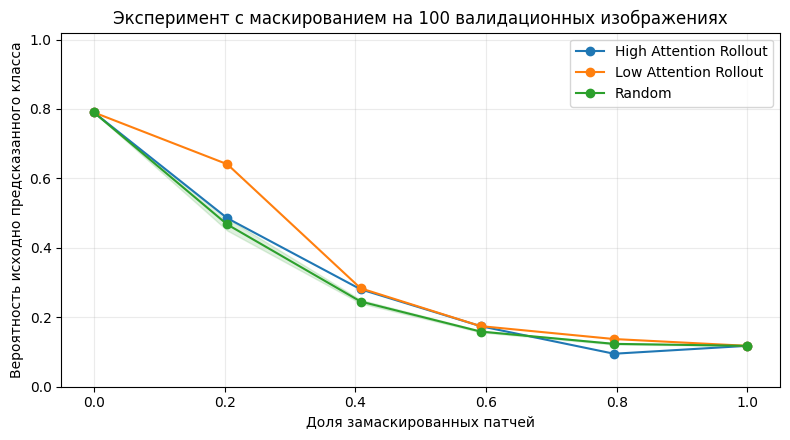

High Attention Rollout: AUC маскирования = 0.299
Low Attention Rollout: AUC маскирования = 0.340
Random              : AUC маскирования = 0.292


In [41]:
# При 0% и 100% входы всех стратегий одинаковы, поэтому результаты должны совпадать.

for curve in (low_curve, *random_curves):
    np.testing.assert_allclose(high_curve[[0, -1]], curve[[0, -1]], atol=1e-5, rtol=1e-4)


fig, ax = plt.subplots(figsize=(8, 4.5))
for name, values in curve_means.items():
    ax.plot(fractions, values, marker="o", label=name)
ax.fill_between(fractions, curve_means['Random'] - random_std,
                curve_means['Random'] + random_std, alpha=0.15, color="tab:green")
ax.set(xlabel='Доля замаскированных патчей', ylabel='Вероятность исходно предсказанного класса',
       title=f"Эксперимент с маскированием на {len(exp_x)} валидационных изображениях", ylim=(0, 1.02))
ax.grid(alpha=0.25); ax.legend()
plt.tight_layout(); plt.show()


auc_results = {}
for name, values in curve_means.items():
    # Интегрирование методом трапеций: явная запись для совместимости с NumPy 1/2.
    area = float(np.sum((values[:-1] + values[1:]) * 0.5 * np.diff(fractions)))
    auc_results[name] = area
    print(f"{name:20s}: AUC маскирования = {area:.3f}")

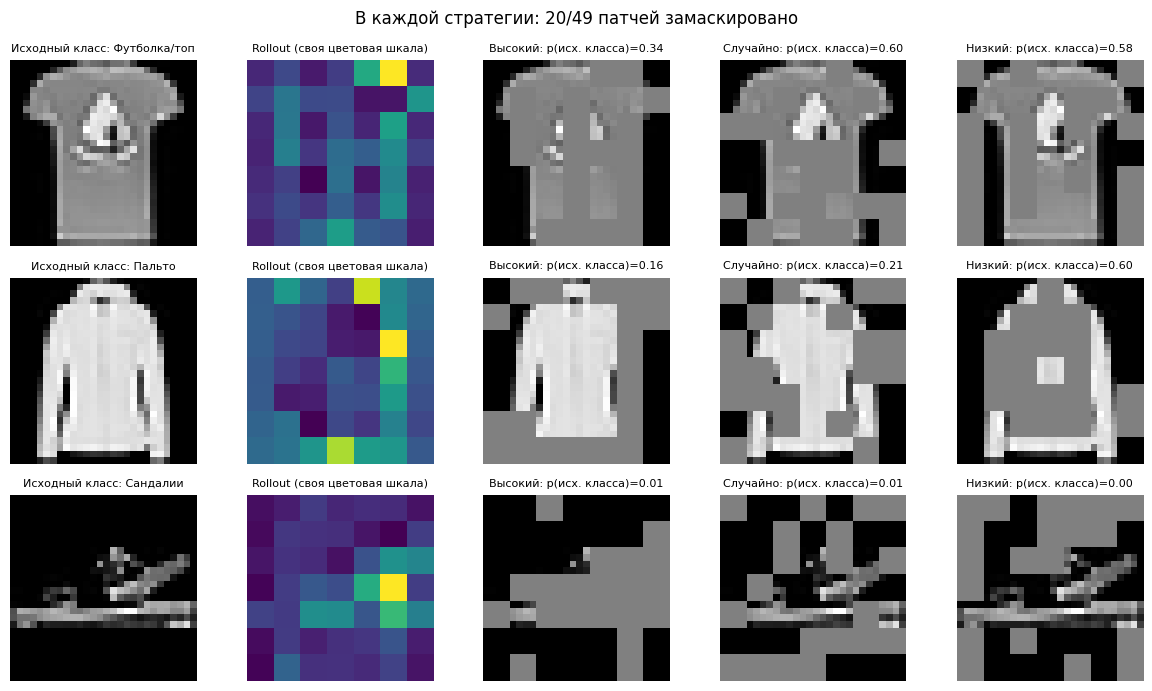

In [42]:
# Показываем первые три фиксированных примера, не отбирая удобные результаты.
count = int(round(0.4 * N))
random_order = rank_patches(rollout_scores, "random", torch.Generator().manual_seed(SEED + 100))
masked_versions = [mask_patches(exp_x, order, count, model.patch_size)
                   for order in (high_order, random_order, low_order)]


with torch.no_grad():
    masked_probabilities = [model(batch).softmax(-1).gather(1, fixed_classes[:, None]).squeeze(1)
                            for batch in masked_versions]


fig, axes = plt.subplots(3, 5, figsize=(12, 7))
grid = IMAGE_SIZE // model.patch_size

for i in range(3):
    axes[i, 0].imshow((exp_x[i, 0].cpu() + 1) / 2, cmap="gray", vmin=0, vmax=1)
    axes[i, 0].set_title(f"Исходный класс: {class_names[int(fixed_classes[i])]}", fontsize=8)
    axes[i, 1].imshow(rollout_scores[i].reshape(grid, grid).cpu(), cmap="viridis")
    axes[i, 1].set_title('Rollout (своя цветовая шкала)', fontsize=8)
    for j, name in enumerate(('Высокий', 'Случайно', 'Низкий')):
        axes[i, j+2].imshow((masked_versions[j][i, 0].cpu() + 1) / 2, cmap="gray", vmin=0, vmax=1)
        axes[i, j+2].set_title(f"{name}: p(исх. класса)={float(masked_probabilities[j][i]):.2f}", fontsize=8)


for ax in axes.ravel():
    ax.axis("off")
fig.suptitle(f"В каждой стратегии: {count}/{N} патчей замаскировано", fontsize=12)
plt.tight_layout(); plt.show()

**Обсуждение**

1. У какой стратегии самая низкая AUC? Сохраняется ли порядок стратегий при разных долях маскирования?
    - В среднем -- случайное маскирование. То есть маскирование патчей с высоким rollout attention в среднем не подавляет исходный класс сильнее чем случайное.
    - Но при высокой доле маскирования ~0.8 особенно проседает стратегия High: меняется порядок между random и high.
2. Опишите одно показанное изображение, для которого ранжирование по rollout кажется полезным, и одно, для которого результат менее убедителен, если такое есть. Не придумывайте неудачный пример, если показанные изображения его не демонстрируют.
    - Футболка: маскирование по high rollout закрывает принт, важный для классификации футболки.
3. Почему при сравнении стратегий нужно фиксировать отслеживаемый класс, число маскируемых патчей, значение заполнения маски и сами изображения?
    -  Для чистоты эксперимента: выделить влияние самой стратегии.
4. Приведите две причины, по которым этот эксперимент не доказывает, что rollout достоверно объясняет, «куда смотрит модель».
    - Усреднение по головам (а они могут "смотреть" в разные места)
    - Rollout - линейное приближение, теряется нелиинейность.

**7. Снижение размера патчей**
- обучение новой модели (P=7)
- сравнение с базовой моделью (P=4)
- разбиение, размер батча, количество эпох, оптимизитор, планировщик lr, гиперпараметры модели остаются такими же -> такое же число обработанных примеров и шагов оптимизации, но не общее время обучения

**7.1 Объём вычислений**
- кол-во патчей N = (H / P) ** 2
- токены T = N + 1
- кол-во элементов матрицы оценок внимания (изображение, голова, слой) = T ** 2

In [43]:
def patch_statistics(image_size: int, patch_size: int) -> dict[str, int]:
    assert image_size % patch_size == 0

    n_patches = (image_size // patch_size) ** 2
    n_tokens = n_patches + 1
    n_attn_entries = n_tokens ** 2

    return {
        "patches": n_patches,
        "tokens": n_tokens,
        "attention_entries": n_attn_entries,
    }

In [44]:
OTHER_PATCH_SIZE = 7
assert patch_statistics(28, 4) == {"patches": 49, "tokens": 50, "attention_entries": 2500}
assert patch_statistics(28, 7) == {"patches": 16, "tokens": 17, "attention_entries": 289}
for p in (PATCH_SIZE, OTHER_PATCH_SIZE):
    print(f"P={p}:", patch_statistics(IMAGE_SIZE, p))
entry_ratio = (patch_statistics(IMAGE_SIZE, PATCH_SIZE)["attention_entries"] /
               patch_statistics(IMAGE_SIZE, OTHER_PATCH_SIZE)["attention_entries"])
print(f"Отношение числа элементов внимания P={PATCH_SIZE} / P={OTHER_PATCH_SIZE}: {entry_ratio:.2f}×")

P=4: {'patches': 49, 'tokens': 50, 'attention_entries': 2500}
P=7: {'patches': 16, 'tokens': 17, 'attention_entries': 289}
Отношение числа элементов внимания P=4 / P=7: 8.65×


**Предположения**

- Какая модель будет быстрее?
    - С бОльшим размером патча (меньше вычислений)
- Какая может дать более высокое качество?
    - С меньшим размером патча (больше детализация, подробнее пространственные связи между элементами изображения). Однако и обучаться такой модели сложнее.  
- Совпадёт ли отношение времен работы двух моделей с отношением числа элементов матрицы внимания в них?
    - Нет, т.к. модель не состоит единственно из внимания.

P=7 | параметров=605,066 | валидация до обучения: потери=2.353, доля верных ответов=4.0%
эпоха  1/8 | потери на обучении 1.490, доля верных 51.1% | потери на валидации 1.009, доля верных 67.3% | обучение 0.8с
эпоха  2/8 | потери на обучении 0.833, доля верных 73.6% | потери на валидации 0.736, доля верных 74.5% | обучение 0.8с
эпоха  3/8 | потери на обучении 0.662, доля верных 77.7% | потери на валидации 0.667, доля верных 77.8% | обучение 0.7с
эпоха  4/8 | потери на обучении 0.584, доля верных 79.8% | потери на валидации 0.595, доля верных 79.8% | обучение 0.7с
эпоха  5/8 | потери на обучении 0.537, доля верных 82.0% | потери на валидации 0.540, доля верных 81.0% | обучение 0.7с
эпоха  6/8 | потери на обучении 0.480, доля верных 83.4% | потери на валидации 0.515, доля верных 82.0% | обучение 0.8с
эпоха  7/8 | потери на обучении 0.447, доля верных 84.5% | потери на валидации 0.493, доля верных 83.5% | обучение 0.7с
эпоха  8/8 | потери на обучении 0.427, доля верных 84.9% | потери на ва

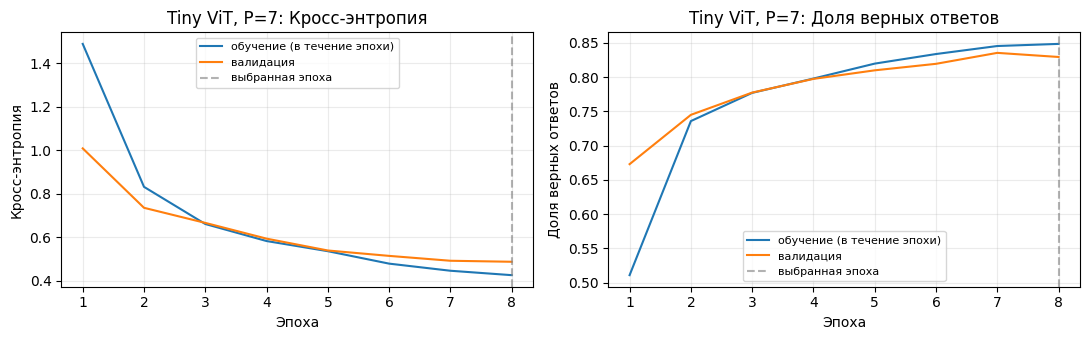

In [45]:
seed_everything(SEED)
other_model = TinyViT(**model_config(OTHER_PATCH_SIZE)).to(device)
other_result = fit_model(other_model)
plot_history(other_result, f"Tiny ViT, P={OTHER_PATCH_SIZE}")
model = main_result["model"]



Результаты

  P  токены    параметры     шаги    обуч., с кач. вал.  пот. вал.
  4      50      605,066      632        10.9     80.3%      0.561
  7      17      605,066      632         5.9     83.0%      0.488
Отношение измеренного времени обучения P=4 / P=7: 1.83×


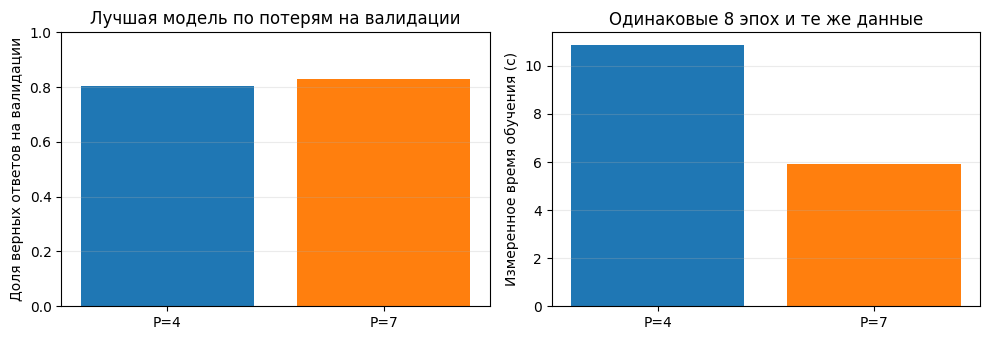

In [46]:
comparison = {
    PATCH_SIZE: main_result,
    OTHER_PATCH_SIZE: other_result,
    }

print(f"{'P':>3} {'токены':>7} {'параметры':>12} {'шаги':>8} {'обуч., с':>11} {'кач. вал.':>9} {'пот. вал.':>10}")


for p, result in comparison.items():
    stats = patch_statistics(IMAGE_SIZE, p)

    print(f"{p:3d} {stats['tokens']:7d} {result['parameters']:12,d} {result['updates']:8d} "
          f"{result['train_seconds']:11.1f} {result['val_acc']:9.1%} {result['val_loss']:10.3f}")


assert main_result["updates"] == other_result["updates"]
print(f"Отношение измеренного времени обучения P={PATCH_SIZE} / P={OTHER_PATCH_SIZE}: "
      f"{main_result['train_seconds'] / other_result['train_seconds']:.2f}×")



fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
names = [f"P={p}" for p in comparison]
axes[0].bar(names, [r["val_acc"] for r in comparison.values()], color=["tab:blue", "tab:orange"])
axes[0].set(ylabel='Доля верных ответов на валидации', ylim=(0, 1), title='Лучшая модель по потерям на валидации')
axes[1].bar(names, [r["train_seconds"] for r in comparison.values()], color=["tab:blue", "tab:orange"])
axes[1].set(ylabel='Измеренное время обучения (с)', title=f"Одинаковые {EPOCHS} эпох и те же данные")
for ax in axes:
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout(); plt.show()

1) Сравнить обе модели по точности на валидации, времени обучения, количеству токенов и числу параметров
    - Модель с патчами бОльшего размера показывает качество -> базовой. Количество токенов и в обучения меньше. Число параметров совпадает.
    - Более глубокая детализация (патчи меньшего размера) требует больше вычислений: длина входной последовательности токенов увеличивается. Для рассматриваемой задачи достаточно патчей размера 7: увеличение детализации не приводит к повышению качества.
    - Возможно, обучение на большем кол-ве эпох показало бы иную картину: по кривым обучения видно, что потенциал ещё есть.
2) Почему отношение числа элементов матрицы внимания отличается от отношения времени работы?
    - Время работы складывается из совокупности вычислительных блоков модели (и их сложности по длине последовательностии), а не только блоков внимания.
    - Например, операция свертки "дороже" для более крупных патчей, что корректирует отношение времени работы.
3) Оправдывает ли более мелкая сетка патчей (патчи меньшего размера) дополнительные затраты при том же кол-ве эпох? Критерий.
    - Для рассматриваемой задачи (классификация крупного и центрированного объекта) нет. Критерий: точность мультиклассовой (классы сбалансированы) классификации на валидации при обучении на 8 эпохах.
    - Также уместно сравнивать, фиксируя не кол-во эпох, а общее время обучения.
4) Какие выводы можно и нельзя сделать по одному seed на этом датасете? Ответило бы сравнение при одинаковом времени обучения на тот же вопрос?
    - Можно: наблюдается разница в качестве и скорости обучения на этом запуске.
    - Нельзя: что разница стат значима. Что скорость всегда быстрее.
    - Не совсем: при одинаковом времени обучения мы лучше понимаем эффективность моделей при заданных ресурсах (бюджете).

**8. Итоговая оценка на тестовой выборке**
- выбрать размер пачта по функции потерь на валидации, оценить


Выбрано P=7 по потерям на валидации
ТЕСТ | 10000 изображений | потери=0.490 | доля верных ответов=82.8%


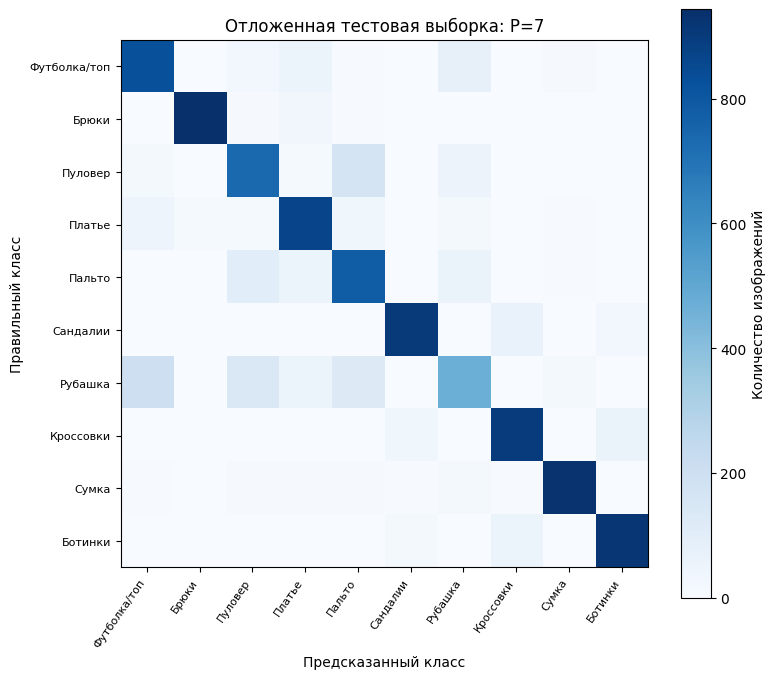

In [47]:
selected_patch_size = min(comparison, key=lambda p: comparison[p]["val_loss"])
selected_model = comparison[selected_patch_size]["model"]


test_metrics = evaluate(selected_model, make_loader(test_set))

print(f"Выбрано P={selected_patch_size} по потерям на валидации")
print(f"ТЕСТ | {len(test_set)} изображений | потери={test_metrics['loss']:.3f} | доля верных ответов={test_metrics['accuracy']:.1%}")


confusion = torch.zeros(N_CLASSES, N_CLASSES, dtype=torch.long)
selected_model.eval()
with torch.inference_mode():
    for x, y in make_loader(test_set):
        prediction = selected_model(x.to(device)).argmax(dim=-1).cpu()
        confusion += torch.bincount(y * N_CLASSES + prediction,
                                    minlength=N_CLASSES ** 2).reshape(N_CLASSES, N_CLASSES)



fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(confusion.numpy(), cmap="Blues")
ax.set_xticks(range(N_CLASSES), labels=class_names, rotation=55, ha="right", fontsize=8)
ax.set_yticks(range(N_CLASSES), labels=class_names, fontsize=8)
ax.set(xlabel='Предсказанный класс', ylabel='Правильный класс', title=f"Отложенная тестовая выборка: P={selected_patch_size}")
plt.colorbar(im, ax=ax, label='Количество изображений')
plt.tight_layout(); plt.show()